# Resultados: tabelas e figuras

Este notebook **não treina nada**. Ele lê os `.json` de resultado de cada experimento declarado em [`configs/`](../configs/), um arquivo por execução, e gera as tabelas e as figuras com o pacote `parallel_pinns`.

- `PASTA_RESULTADOS = "exploratorio"` usa os resultados da versão exploratória (tag `v0.1.0-exploratorio`), que têm os mesmos nomes de arquivo.
- Depois da execução final (`python -m parallel_pinns.cli.run_experiment configs/<experimento>.yaml`), basta trocar para `"final"`: os resultados passam a vir de `results/<experimento>/`, e o manifesto de cada pasta registra o commit e a plataforma.

In [1]:
import sys
from pathlib import Path

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ / "src"))          # dispensa a instalacao do pacote

import matplotlib.pyplot as plt
import numpy as np

from parallel_pinns.statistics import comparar_razao, desfecho_h2, falhou, resumo_log, tost_log
from parallel_pinns.tracking import carregar_config, carregar_resultados

PASTA_RESULTADOS = "exploratorio"              # "exploratorio" ou "final"


def resultados(experimento):
    cfg = carregar_config(RAIZ / "configs" / f"{experimento}.yaml")
    pasta = RAIZ / "notebooks" / "exploratorio" if PASTA_RESULTADOS == "exploratorio" else RAIZ / "results" / experimento
    return carregar_resultados(cfg, pasta)


def selecionar(lista, **filtro):
    return [r for t, r in lista if all(t.get(k) == v for k, v in filtro.items())]


l2 = lambda rs: [r["metricas"]["L2"] for r in rs]
print("resultados de:", PASTA_RESULTADOS)

resultados de: exploratorio


## H1: o DDP preserva a acurácia? (P1, 20 sementes, 5000 iterações)

TOST pareado em log10 com margem $[0{,}8;\ 1{,}25]$ e Bonferroni ($p < 0{,}025$ em cada teste). Ao lado, o Hodges–Lehmann e o Wilcoxon, robustos a valores extremos.

In [2]:
ddp = resultados("ddp_tost")
seq = l2(selecionar(ddp, p=1))
print(f"{'':>8} {'razão geom.':>11} {'IC 90%':>16} {'p TOST':>7} {'Hodges-Lehmann':>15} {'Wilcoxon p':>11}")
for p in (2, 4):
    razao, (lo, hi), p_tost = tost_log(l2(selecionar(ddp, p=p)), seq)
    r = comparar_razao(l2(selecionar(ddp, p=p)), seq)
    print(f"{'p = ' + str(p):>8} {razao:11.2f} {f'[{lo:.2f}; {hi:.2f}]':>16} {p_tost:7.2f} {r['hodges_lehmann']:15.2f} {r['p_wilcoxon']:11.3g}")

xd = resultados("xpinn_distribuido")
razao, (lo, hi), p_tost = tost_log(l2(selecionar(xd, p=4)), l2(selecionar(xd, p=1)))
print(f"\nXPINN distribuído (M = 2, p = 4) / sequencial: razão {razao:.2f}, IC 90% [{lo:.2f}; {hi:.2f}], p TOST = {p_tost:.1e}")

         razão geom.           IC 90%  p TOST  Hodges-Lehmann  Wilcoxon p
   p = 2        0.86     [0.67; 1.09]    0.31            0.93       0.202
   p = 4        0.80     [0.63; 1.01]    0.50            0.90     0.00944



XPINN distribuído (M = 2, p = 4) / sequencial: razão 1.01, IC 90% [0.96; 1.06], p TOST = 1.3e-05


## Ordem das somas: o sequencial em `float64`

In [3]:
seq64 = l2(selecionar(resultados("ordem_somas")))
for rotulo, a, b in [("float64 / float32 (sequencial)", seq64, seq),
                     ("DDP p=4 / sequencial float64", l2(selecionar(ddp, p=4)), seq64),
                     ("DDP p=4 / sequencial float32", l2(selecionar(ddp, p=4)), seq)]:
    r = comparar_razao(a, b)
    print(f"{rotulo:>32}: razão {r['razao']:.3f} | IC 90% [{r['ic90'][0]:.3f}; {r['ic90'][1]:.3f}] | "
          f"Hodges-Lehmann {r['hodges_lehmann']:.3f} | Wilcoxon p = {r['p_wilcoxon']:.3g}")

  float64 / float32 (sequencial): razão 0.729 | IC 90% [0.586; 0.905] | Hodges-Lehmann 0.816 | Wilcoxon p = 0.000105
    DDP p=4 / sequencial float64: razão 1.098 | IC 90% [1.033; 1.168] | Hodges-Lehmann 1.081 | Wilcoxon p = 0.0192
    DDP p=4 / sequencial float32: razão 0.800 | IC 90% [0.634; 1.009] | Hodges-Lehmann 0.899 | Wilcoxon p = 0.00944


## H2: XPINN $M = 4$ contra a monolítica acima do limiar

Ajuste da monolítica ($\lambda_{BC}$, critério fixado antes), depois o teste confirmatório com as sementes 20 a 29: Wilcoxon bilateral, $\alpha = 0{,}025$ por $n$, sentido pelo Hodges–Lehmann.

E_L2 geométrico por lam_BC: {0.1: '7.91e-03', 0.3: '6.46e-03', 1.0: '5.28e-03', 3.0: '1.09e-02'} -> escolhido: 1.0

  n                 comparação  Hodges-Lehmann  XPINN pior  Wilcoxon p                   desfecho  falhas mono/XPINN
 13   XPINN / monolítica (GPU)           0.189        2 de 10      0.0645   sem diferença detectável          5 / 2
 15   XPINN / monolítica (GPU)           0.082        0 de 10     0.00195              H2 confirmada          8 / 0
 15   XPINN / monolítica (CPU)           0.094        0 de 10     0.00195              H2 confirmada          6 / 0


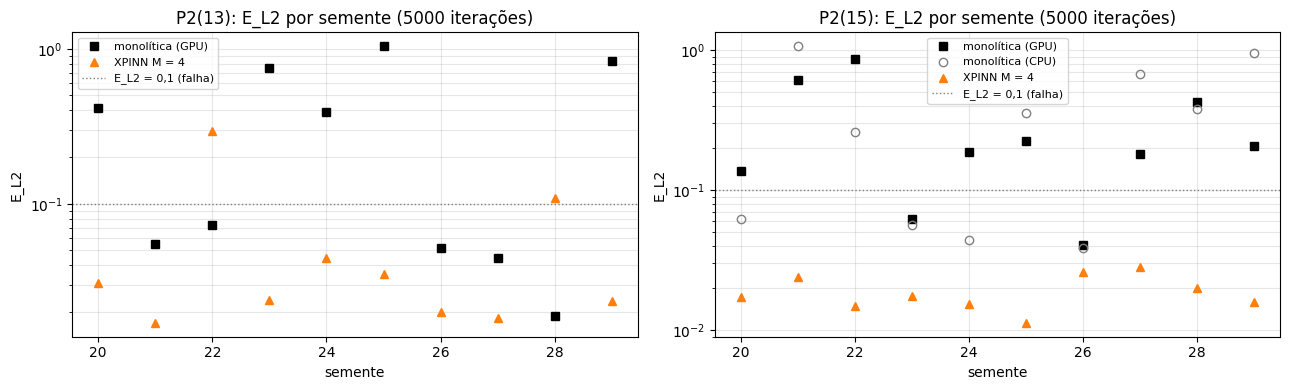

In [4]:
lam = resultados("escolha_lam_bc")
geom = {l: resumo_log([r["metricas"]["L2"] for t, r in lam if t["lam_bc"] == l])[0] for l in sorted({t["lam_bc"] for t, _ in lam})}
print("E_L2 geométrico por lam_BC:", {l: f"{g:.2e}" for l, g in geom.items()}, "-> escolhido:", min(geom, key=geom.get))

h2, cpu = resultados("h2_confirmatorio"), resultados("verificacao_cpu")
print(f"\n{'n':>3} {'comparação':>26} {'Hodges-Lehmann':>15} {'XPINN pior':>11} {'Wilcoxon p':>11} {'desfecho':>26} {'falhas mono/XPINN':>18}")
for n in (13, 15):
    xp = [r["metricas"] for r in selecionar(h2, n=n, M=4)]
    referencias = [("monolítica (GPU)", [r["metricas"] for r in selecionar(h2, n=n, dispositivo="cuda")])]
    if n == 15:
        referencias.append(("monolítica (CPU)", [r["metricas"] for _, r in cpu]))
    for rotulo, mono in referencias:
        r = comparar_razao([m["L2"] for m in xp], [m["L2"] for m in mono])
        d = desfecho_h2(r["p_wilcoxon"], np.log10(r["hodges_lehmann"]), alfa=0.025)
        print(f"{n:>3} {'XPINN / ' + rotulo:>26} {r['hodges_lehmann']:15.3f} {r['pior_em']:>8} de {r['n']} "
              f"{r['p_wilcoxon']:11.3g} {d:>26} {sum(map(falhou, mono)):>10} / {sum(map(falhou, xp))}")

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for a, n in zip(ax, (13, 15)):
    sementes = [t["semente"] for t, _ in h2 if t["n"] == n and t.get("M") == 4]
    a.semilogy(sementes, l2(selecionar(h2, n=n, dispositivo="cuda")), "s", color="k", label="monolítica (GPU)")
    if n == 15:
        a.semilogy(sementes, l2([r for _, r in cpu]), "o", mfc="none", color="gray", label="monolítica (CPU)")
    a.semilogy(sementes, l2(selecionar(h2, n=n, M=4)), "^", color="tab:orange", label="XPINN M = 4")
    a.axhline(0.1, color="gray", ls=":", lw=1, label="E_L2 = 0,1 (falha)")
    a.set(title=f"P2({n}): E_L2 por semente (5000 iterações)", xlabel="semente", ylabel="E_L2")
    a.grid(True, which="both", alpha=.3)
    a.legend(fontsize=8)
plt.tight_layout()
plt.show()